In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Netflix dataset
df = pd.read_csv('/content/netflix_titles.csv')

# Display first 5 rows
df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [11]:

# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (8807, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Missing Values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             

In [12]:

# Check duplicate records
print("Total duplicate rows:", df.duplicated().sum())

# Check duplicate show IDs
print("Duplicate show IDs:", df['show_id'].duplicated().sum())


Total duplicate rows: 0
Duplicate show IDs: 0


In [13]:

# Create a separate cleaned copy
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates(subset=['show_id'])

# Fill missing values in selected columns
columns_to_fill = ['director', 'cast', 'country', 'rating', 'duration']

for col in columns_to_fill:
    df_clean[col] = df_clean[col].fillna('Unknown')

# Convert date_added into proper date format
df_clean['date_added'] = pd.to_datetime(
    df_clean['date_added'],
    format='%B %d, %Y',
    errors='coerce'
)

# Check remaining missing values
print("Missing values after cleaning:")
print(df_clean.isnull().sum())


Missing values after cleaning:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      98
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


In [14]:

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

df_clean.head()


Original dataset shape: (8807, 12)
Cleaned dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


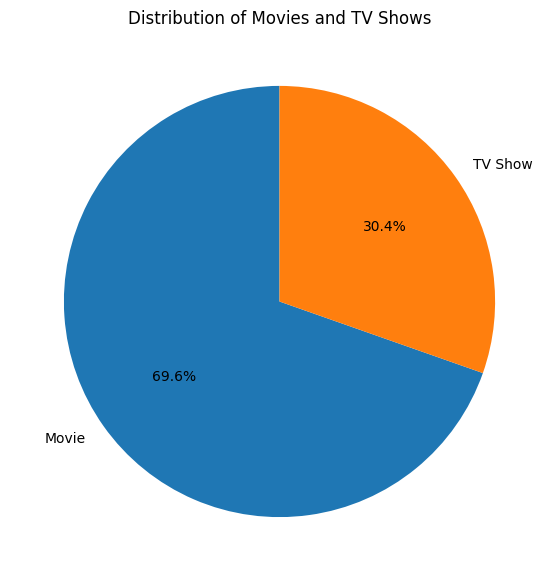

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


In [15]:

# Count Movies and TV Shows
content_count = df_clean['type'].value_counts()

# Create a pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    content_count,
    labels=content_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Movies and TV Shows')
plt.show()

# Display actual counts
print(content_count)


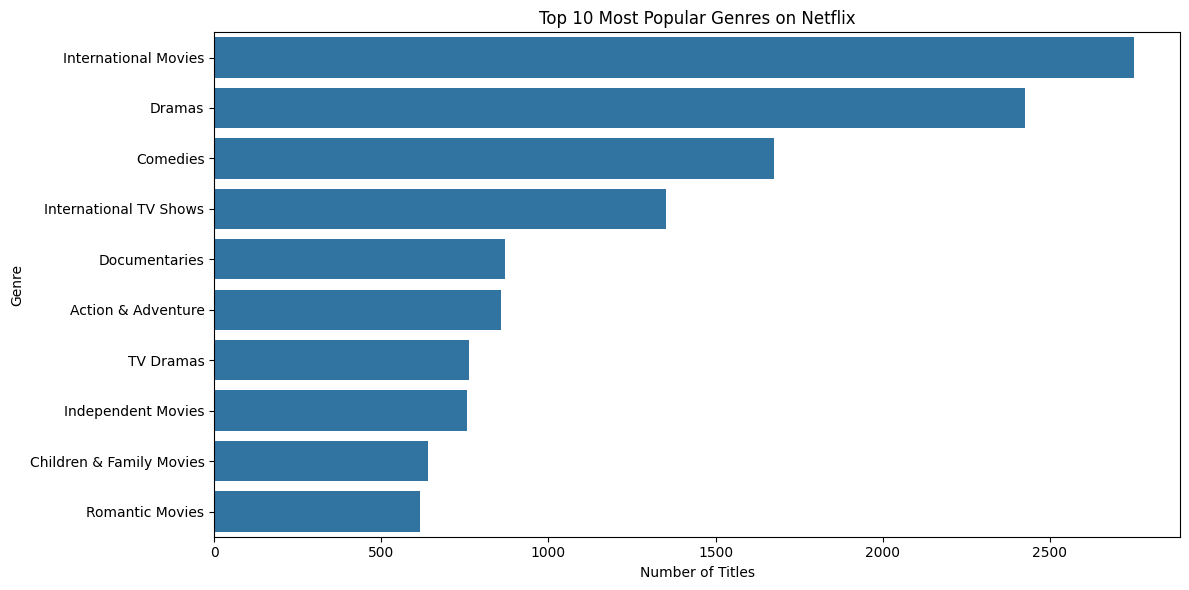

listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


In [16]:

# Split genres because each title can have multiple genres
genres = df_clean['listed_in'].str.split(', ')

# Count each genre
genre_counts = genres.explode().value_counts()

# Select the top 10 genres
top_10_genres = genre_counts.head(10)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_genres.values,
    y=top_10_genres.index
)

plt.title('Top 10 Most Popular Genres on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

# Display genre counts
print(top_10_genres)


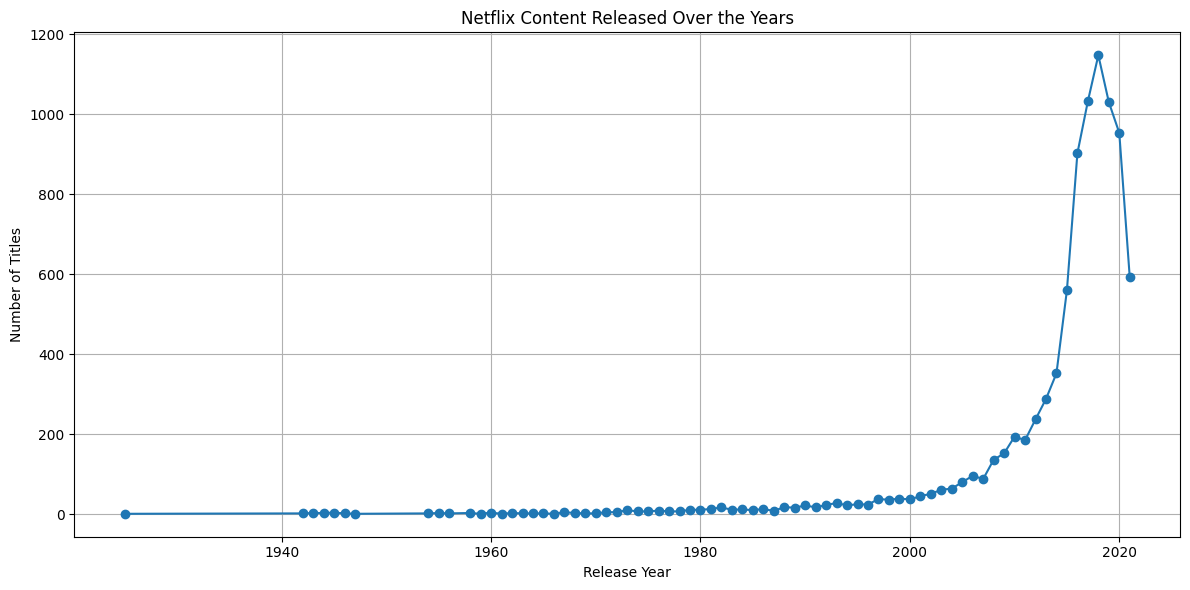

In [17]:

# Count titles released each year
year_counts = df_clean['release_year'].value_counts().sort_index()

# Create a line chart
plt.figure(figsize=(12, 6))

plt.plot(
    year_counts.index,
    year_counts.values,
    marker='o'
)

plt.title('Netflix Content Released Over the Years')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.grid(True)
plt.tight_layout()
plt.show()


In [18]:

most_common_year = year_counts.idxmax()
total_titles = year_counts.max()

print("Year with the most releases:", most_common_year)
print("Number of titles:", total_titles)


Year with the most releases: 2018
Number of titles: 1147


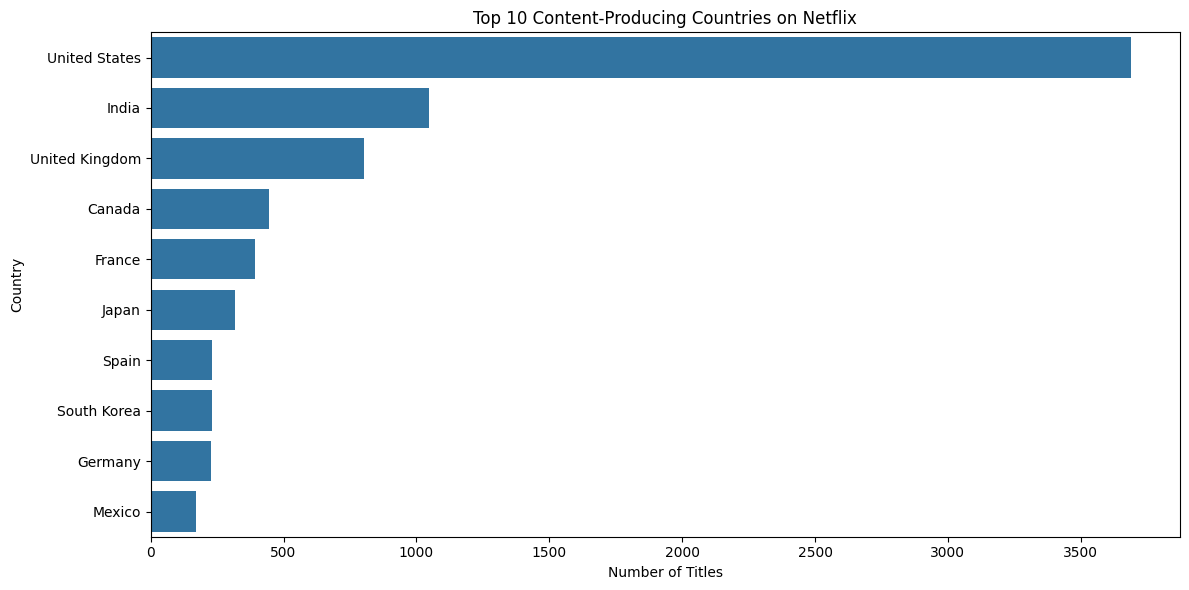

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


In [19]:

# Split country names because a title can have multiple countries
countries = df_clean['country'].str.split(', ')

# Count titles by country
country_counts = countries.explode()

# Remove Unknown values
country_counts = country_counts[country_counts != 'Unknown']

# Find top 10 countries
top_10_countries = country_counts.value_counts().head(10)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index
)

plt.title('Top 10 Content-Producing Countries on Netflix')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

print(top_10_countries)


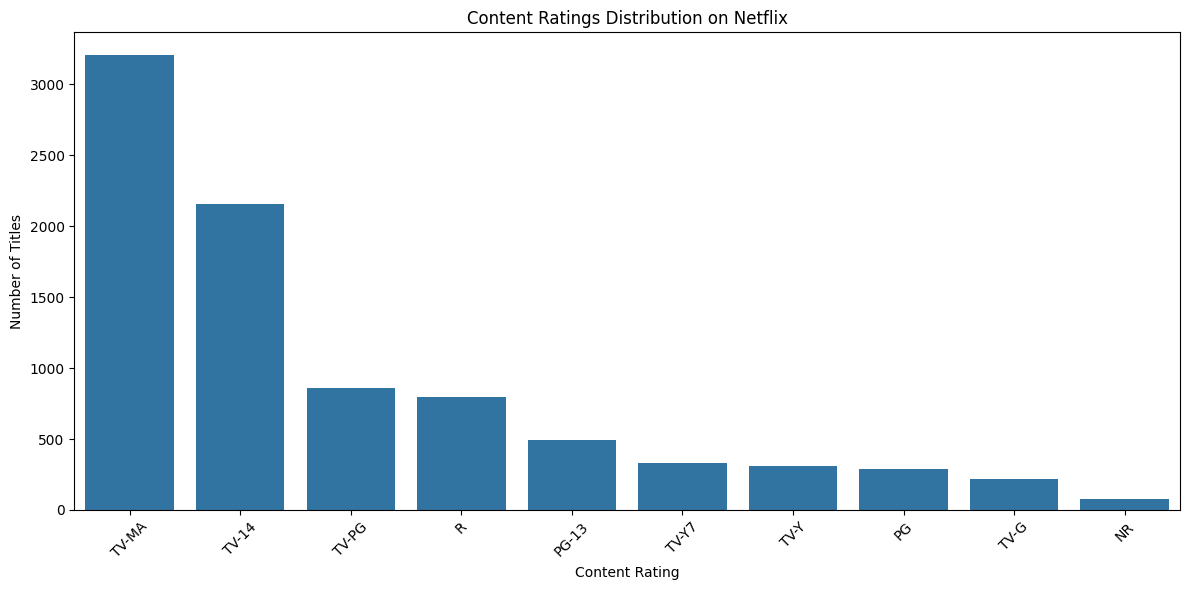

rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64


In [20]:

# Count content ratings
rating_counts = df_clean['rating'].value_counts()

# Select top 10 ratings
top_ratings = rating_counts.head(10)

# Create a bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_ratings.index,
    y=top_ratings.values
)

plt.title('Content Ratings Distribution on Netflix')
plt.xlabel('Content Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display rating counts
print(top_ratings)


In [21]:

# Filter only movies
movies = df_clean[df_clean['type'] == 'Movie'].copy()

# Extract duration in minutes
movies['duration_minutes'] = (
    movies['duration']
    .str.extract(r'(\d+)')
    .astype(float)
)

# Remove missing duration values
movies = movies.dropna(subset=['duration_minutes'])

# Display basic statistics
print("Average Movie Duration:",
      round(movies['duration_minutes'].mean(), 2), "minutes")

print("Shortest Movie:",
      movies['duration_minutes'].min(), "minutes")

print("Longest Movie:",
      movies['duration_minutes'].max(), "minutes")


Average Movie Duration: 99.58 minutes
Shortest Movie: 3.0 minutes
Longest Movie: 312.0 minutes


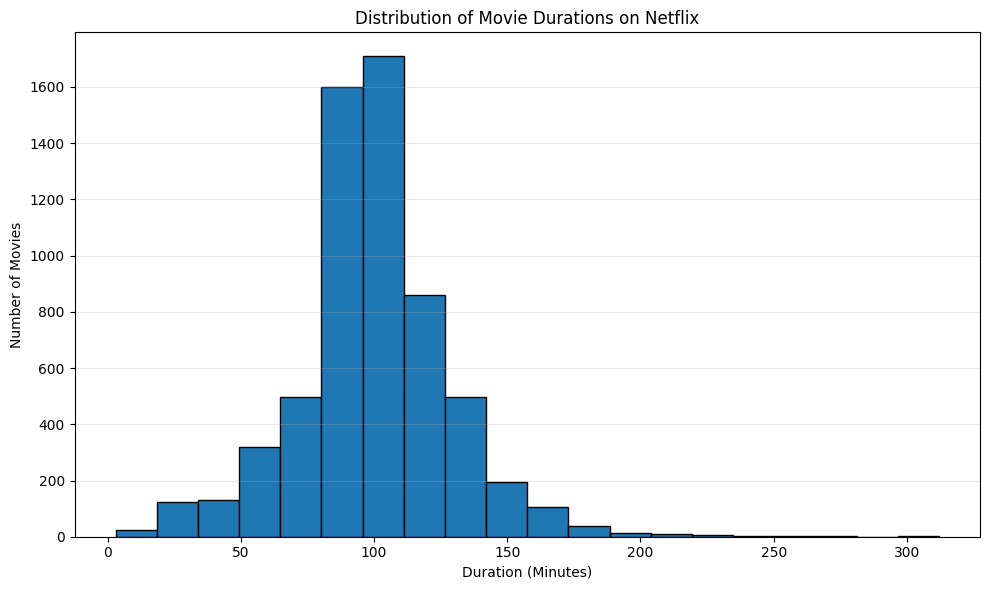

In [22]:

plt.figure(figsize=(10, 6))

plt.hist(
    movies['duration_minutes'],
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of Movie Durations on Netflix')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Movies')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


## Key Business Insights

### 1. Strong International Content Presence
The United States has the highest number of titles (3,689), followed by India (1,046) and the United Kingdom (804).

**Recommendation:** Continue building a strong international content catalogue, with opportunities to expand regional content, especially Indian titles.

### 2. Genre Preferences in the Catalogue
International Movies, Dramas, and Comedies are the three most common genres in the dataset.

**Recommendation:** Continue exploring these genres while introducing a variety of other genres to maintain a diverse catalogue.

### 3. Content Ratings and Movie Duration
TV-MA is the most common content rating, with 3,207 titles. The average movie duration is approximately 99.58 minutes.

**Recommendation:** Maintain a varied content selection for different age groups and consider movies around the average duration when planning future acquisitions.

### Overall Finding
The Netflix catalogue shows a strong presence of movies, international content, and drama-related genres. These findings can help guide content acquisition and catalogue planning.

# Content Strategy Memo
**Project:** OTT Streaming Content Trend Analysis  
**Dataset:** Netflix Titles Dataset  
**Prepared by:** Rabia Khan

## Introduction
This analysis explores Netflix's content catalogue to identify patterns in content types, genres, release years, countries, ratings, and movie durations.

## Key Findings

1. Movies account for approximately 69.6% of the catalogue, while TV Shows account for 30.4%.
2. International Movies are the most frequently listed genre, followed by Dramas and Comedies.
3. The year 2018 recorded the highest number of titles by release year, with 1,147 titles.
4. The United States leads in content production represented in the catalogue, followed by India and the United Kingdom.
5. TV-MA is the most common content rating, with 3,207 titles.
6. The average movie duration is 99.58 minutes.

## Three Actionable Recommendations

**1. Expand International Content**

Continue exploring international productions and regional content opportunities, particularly in markets such as India.

**2. Maintain Genre Diversity**

Build on the strong presence of International Movies, Dramas, and Comedies while maintaining variety across other genres.

**3. Maintain a Balanced Content Catalogue**

Offer content across different age ratings and movie durations to support a wider range of catalogue needs.

## Conclusion

The analysis provides an overview of Netflix's catalogue and highlights patterns that can support content planning and acquisition decisions. Further analysis using viewer engagement and streaming data would help validate these recommendations.

# Content Strategy Memo
**Project:** OTT Streaming Content Trend Analysis  
**Dataset:** Netflix Titles Dataset  
**Prepared by:** Rabia Khan

## Introduction
This analysis explores Netflix's content catalogue to identify patterns in content types, genres, release years, countries, ratings, and movie durations.

## Key Findings

1. Movies account for approximately 69.6% of the catalogue, while TV Shows account for 30.4%.
2. International Movies are the most frequently listed genre, followed by Dramas and Comedies.
3. The year 2018 recorded the highest number of titles by release year, with 1,147 titles.
4. The United States leads in content production represented in the catalogue, followed by India and the United Kingdom.
5. TV-MA is the most common content rating, with 3,207 titles.
6. The average movie duration is 99.58 minutes.

## Three Actionable Recommendations

**1. Expand International Content**

Continue exploring international productions and regional content opportunities, particularly in markets such as India.

**2. Maintain Genre Diversity**

Build on the strong presence of International Movies, Dramas, and Comedies while maintaining variety across other genres.

**3. Maintain a Balanced Content Catalogue**

Offer content across different age ratings and movie durations to support a wider range of catalogue needs.

## Conclusion

The analysis provides an overview of Netflix's catalogue and highlights patterns that can support content planning and acquisition decisions. Further analysis using viewer engagement and streaming data would help validate these recommendations.

In [23]:

import sqlite3

# Create SQLite database
conn = sqlite3.connect('netflix_analysis.db')

# Prepare data for SQL
sql_df = df_clean.copy()
sql_df['date_added'] = sql_df['date_added'].astype(str)

# Store dataset as a SQL table
sql_df.to_sql(
    'netflix_titles',
    conn,
    if_exists='replace',
    index=False
)

print("Netflix dataset successfully loaded into SQL!")


Netflix dataset successfully loaded into SQL!


In [24]:

# Query 1: Count Movies and TV Shows
query1 = """
SELECT type, COUNT(*) AS total_titles
FROM netflix_titles
GROUP BY type;
"""

# Query 2: Top 10 release years
query2 = """
SELECT release_year, COUNT(*) AS total_titles
FROM netflix_titles
GROUP BY release_year
ORDER BY total_titles DESC
LIMIT 10;
"""

# Query 3: Content rating distribution
query3 = """
SELECT rating, COUNT(*) AS total_titles
FROM netflix_titles
GROUP BY rating
ORDER BY total_titles DESC
LIMIT 10;
"""

# Query 4: Top 10 countries
query4 = """
SELECT country, COUNT(*) AS total_titles
FROM netflix_titles
WHERE country != 'Unknown'
GROUP BY country
ORDER BY total_titles DESC
LIMIT 10;
"""

# Query 5: Average movie duration
query5 = """
SELECT
    ROUND(AVG(CAST(REPLACE(duration, ' min', '') AS FLOAT)), 2)
    AS average_movie_duration
FROM netflix_titles
WHERE type = 'Movie'
AND duration LIKE '%min';
"""

# Display results
for i, query in enumerate(
    [query1, query2, query3, query4, query5], 1
):
    print(f"\nSQL QUERY {i}")
    display(pd.read_sql_query(query, conn))



SQL QUERY 1


,type,total_titles
0,Movie,6131
1,TV Show,2676



SQL QUERY 2


,release_year,total_titles
0,2018,1147
1,2017,1032
2,2019,1030
3,2020,953
4,2016,902
5,2021,592
6,2015,560
7,2014,352
8,2013,288
9,2012,237



SQL QUERY 3


,rating,total_titles
0,TV-MA,3207
1,TV-14,2160
2,TV-PG,863
3,R,799
4,PG-13,490
5,TV-Y7,334
6,TV-Y,307
7,PG,287
8,TV-G,220
9,NR,80



SQL QUERY 4


,country,total_titles
0,United States,2818
1,India,972
2,United Kingdom,419
3,Japan,245
4,South Korea,199
5,Canada,181
6,Spain,145
7,France,124
8,Mexico,110
9,Egypt,106



SQL QUERY 5


,average_movie_duration
0,99.58


In [25]:

queries = [query1, query2, query3, query4, query5]

with open('netflix_analysis.sql', 'w') as file:
    for i, query in enumerate(queries, 1):
        file.write(f"-- Query {i}\n")
        file.write(query + "\n\n")

print("SQL file created successfully!")


SQL file created successfully!
